# 5 seeds were trained based on the evaluation of the cql alpha sweep contained in evaluate_cql_alpha_sweep.ipynb

In [26]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.action_distribution_sweep as action_dist
import src.rl.clinician_baseline as clin_baseline
import src.rl.reward_by_vaso_match as vaso_match
import src.rl.dose_histogram_by_alpha as dose_hist
import src.rl.inspect_fluid_params as raw_params
import src.rl.check_std_floor as std_check
import src.rl.diagnose_fluid_spike as spike_diag
import src.rl.plot_fluid_two_population as fluid_pop
import src.rl.plot_fluid_dose_severity_heatmaps as heatmap_diag
import src.rl.final_model_selection as final_select
import src.rl.advantage_distributions_by_seed as adv_dist
import src.rl.occupancy_by_seed as occ_seed
import src.rl.shape_dose_overlap as shape_overlap
import src.rl.dose_response_shapes as analyze_nm

# SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/cql_alpha_sweep"
# os.makedirs(SAVE_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")

    elif health_cohort == "sepsis_picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")


# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

basic_q_health_score_model_dir = os.path.join(basic_q_dir, "health_score_change_only")
basic_q_health_score_model_dirs = etm.get_model_dirs(basic_q_health_score_model_dir)

basic_q_health_score_models = []
for model_dir in basic_q_health_score_model_dirs:
    # load health score sarsa model
    health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams))


Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_202

In [ ]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )

    # print cql value for this model
    print(f"Loaded CQL health-score model from {model_dir}, cql_alpha={health_score_hyperparams['cql_alpha']}")

    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))


Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-235751_073683e4
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-225924_24f16bd0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-232805_87a9aaa

# Load data

In [8]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [12]:
# real clinician non-zero fluid doses, from training data
fluid_doses = processors['train'].rl_dataset["actions"][:, 0]
nonzero_fluid = fluid_doses[fluid_doses > 1e-4]

# clamp to avoid inf at exact 0/1 boundaries, then invert the sigmoid (logit)
nonzero_fluid_clamped = nonzero_fluid.clamp(1e-4, 1 - 1e-4)
raw_fluid = torch.logit(nonzero_fluid_clamped)

print(f"Fluid: dose-space std={nonzero_fluid.std():.4f}, "
      f"raw-space std={raw_fluid.std():.4f}, raw-space mean={raw_fluid.mean():.4f}")

# same for vaso
vaso_doses = processors['train'].rl_dataset["actions"][:, 1]
nonzero_vaso = vaso_doses[vaso_doses > 1e-4]
nonzero_vaso_clamped = nonzero_vaso.clamp(1e-4, 1 - 1e-4)
raw_vaso = torch.logit(nonzero_vaso_clamped)

print(f"Vaso: dose-space std={nonzero_vaso.std():.4f}, "
      f"raw-space std={raw_vaso.std():.4f}, raw-space mean={raw_vaso.mean():.4f}")

actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

Fluid: dose-space std=0.1420, raw-space std=0.6721, raw-space mean=0.1841
Vaso: dose-space std=0.1158, raw-space std=0.6342, raw-space mean=-1.0675
Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615
=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569
=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


## health_score

In [13]:
training_health_score = processors['train'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
training_health_score = np.delete(training_health_score, indices_to_remove)

val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

training_actions = processors['train'].rl_dataset["actions"]

# standard deviation
### "seed 4 showed a degenerate vaso magnitude std distribution (bimodal at clamp extremes); this had negligible practical effect given vaso's near-zero firing rate for this seed, but is noted as a seed-level irregularity."

Floor std = 0.1353, Ceiling std = 2.7183

Seed    Drug        mean     std     min     max  median   %floor   %ceil
-----------------------------------------------------------------------
1       Fluid     0.7548  0.5652  0.1982  2.7183  0.5828     0.0%    4.6%
1       Vaso      0.7637  0.2906  0.4735  2.7183  0.6605     0.0%    0.3%
2       Fluid     0.7164  0.5346  0.2005  2.7183  0.5360     0.0%    4.0%
2       Vaso      0.5793  0.1771  0.3010  1.7930  0.5267     0.0%    0.0%
3       Fluid     0.7475  0.5617  0.1767  2.7183  0.5945     0.0%    5.2%
3       Vaso      0.8154  0.4384  0.4172  2.7183  0.6710     0.0%    3.0%
4       Fluid     0.8077  0.6236  0.1814  2.7183  0.5960     0.0%    6.1%
4       Vaso      1.9080  1.0316  0.1353  2.7183  2.7183     7.6%   53.8%
5       Fluid     0.7952  0.6323  0.1929  2.7183  0.5953     0.0%    7.2%
5       Vaso      0.6683  0.3050  0.3487  2.7183  0.5507     0.0%    0.1%

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_wi

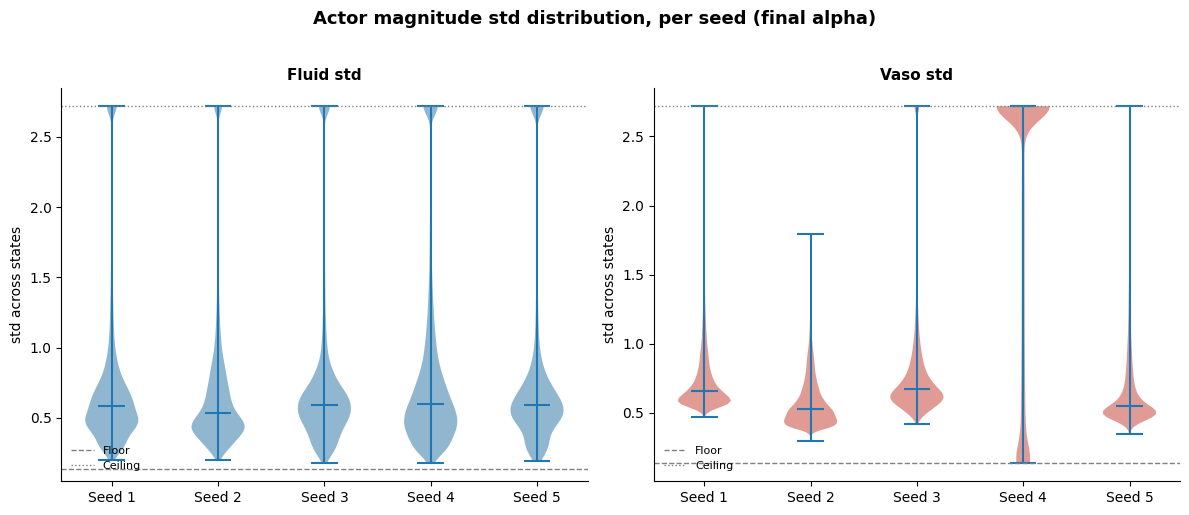

In [14]:
fig = std_check.plot_std_distributions_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    save_path=os.path.join(cql_model_dir, "std_distributions_by_seed_health_score.png"),
)
fig

"Co-occurrence of ceiling-saturated magnitude standard deviation and near-maximal fluid dosing

We tested whether the residual near-maximal (>0.9) fluid dose recommendations identified throughout this analysis co-occur with states where the actor's fluid magnitude standard deviation is saturated at its clamp ceiling, on the held-out test set, across all 5 final seeds. A meaningful and consistent association was present: 41–74% of high-dose states also showed ceiling-saturated magnitude std (mean ≈ 55%, seed 2 the notable outlier at 74%), while a smaller but still non-trivial 14–43% of ceiling-saturated states corresponded to a high-dose recommendation. This asymmetry indicates that magnitude-variance saturation is a broader phenomenon than the extreme-dose pathology specifically — most ceiling-saturated states do not in fact yield a near-maximal dose — but that a substantial minority-to-majority of the extreme-dose recommendations are accompanied by this internal saturation signature, consistent with both symptoms arising from a shared underlying instability in the actor's magnitude parameterization at these states, rather than being independent phenomena.

Given this partial but incomplete overlap, we do not consider magnitude standard deviation alone a sufficiently sensitive or specific signal to serve as a stand-alone clinical safety flag: using it in isolation would miss a substantial fraction of the problematic recommendations (those without ceiling-saturated std) while over-flagging a larger set of states where saturation is present but the resulting dose is unremarkable. We instead propose data-support (occupancy) at the recommended dose, evaluated per-recommendation against the training distribution stratified by patient severity, as the primary mechanism for flagging low-confidence recommendations to clinicians (Section [X]); the std/dose co-occurrence result reported here is presented as corroborating mechanistic evidence for the origin of the residual extreme-dose behavior, not as an alternative or additional clinical safeguard.

This association was directionally consistent but showed some variability across seeds and evaluation splits (e.g., seed 2's overlap fraction was 49.8% on the validation set and 74.2% on the held-out test set for the same trained model), consistent with sampling noise in these relatively small sub-populations rather than genuine seed-level instability."

In [15]:
for seed_idx, _ in enumerate(cql_health_score_fixed_alpha_models):
    print(f"Checking std dose co-occurrence for seed {seed_idx}...")
    ceiling_mask, high_dose_mask = std_check.check_std_dose_cooccurrence(
        cql_health_score_fixed_alpha_models[seed_idx],  # one seed at a time
        processors['test'],
        dim=0,  # fluid
    )

Checking std dose co-occurrence for seed 0...
Ceiling-std states: 5375 (4.61% of all states)
High-dose (>0.9) states: 2453 (2.10% of all states)
States that are BOTH: 1207
  Fraction of ceiling-std states that are ALSO high-dose: 22.5%
  Fraction of high-dose states that are ALSO ceiling-std: 49.2%
Checking std dose co-occurrence for seed 1...
Ceiling-std states: 4682 (4.01% of all states)
High-dose (>0.9) states: 1649 (1.41% of all states)
States that are BOTH: 681
  Fraction of ceiling-std states that are ALSO high-dose: 14.5%
  Fraction of high-dose states that are ALSO ceiling-std: 41.3%
Checking std dose co-occurrence for seed 2...
Ceiling-std states: 6058 (5.19% of all states)
High-dose (>0.9) states: 1334 (1.14% of all states)
States that are BOTH: 990
  Fraction of ceiling-std states that are ALSO high-dose: 16.3%
  Fraction of high-dose states that are ALSO ceiling-std: 74.2%
Checking std dose co-occurrence for seed 3...
Ceiling-std states: 7111 (6.10% of all states)
High-dose

# advantage

Computing advantage for seed 1/5...


    own-critic Q IQR (real clinician actions): 3.2691
    SARSA seed 1 Q IQR (real clinician actions): 0.9590
    SARSA seed 2 Q IQR (real clinician actions): 1.0164
    SARSA seed 3 Q IQR (real clinician actions): 0.9705
    SARSA seed 4 Q IQR (real clinician actions): 1.0574
    SARSA seed 5 Q IQR (real clinician actions): 1.0174
Computing advantage for seed 2/5...
    own-critic Q IQR (real clinician actions): 2.8881
    SARSA seed 1 Q IQR (real clinician actions): 0.9590
    SARSA seed 2 Q IQR (real clinician actions): 1.0164
    SARSA seed 3 Q IQR (real clinician actions): 0.9705
    SARSA seed 4 Q IQR (real clinician actions): 1.0574
    SARSA seed 5 Q IQR (real clinician actions): 1.0174
Computing advantage for seed 3/5...
    own-critic Q IQR (real clinician actions): 2.7309
    SARSA seed 1 Q IQR (real clinician actions): 0.9590
    SARSA seed 2 Q IQR (real clinician actions): 1.0164
    SARSA seed 3 Q IQR (real clinician actions): 0.9705
    SARSA seed 4 Q IQR (real clinician

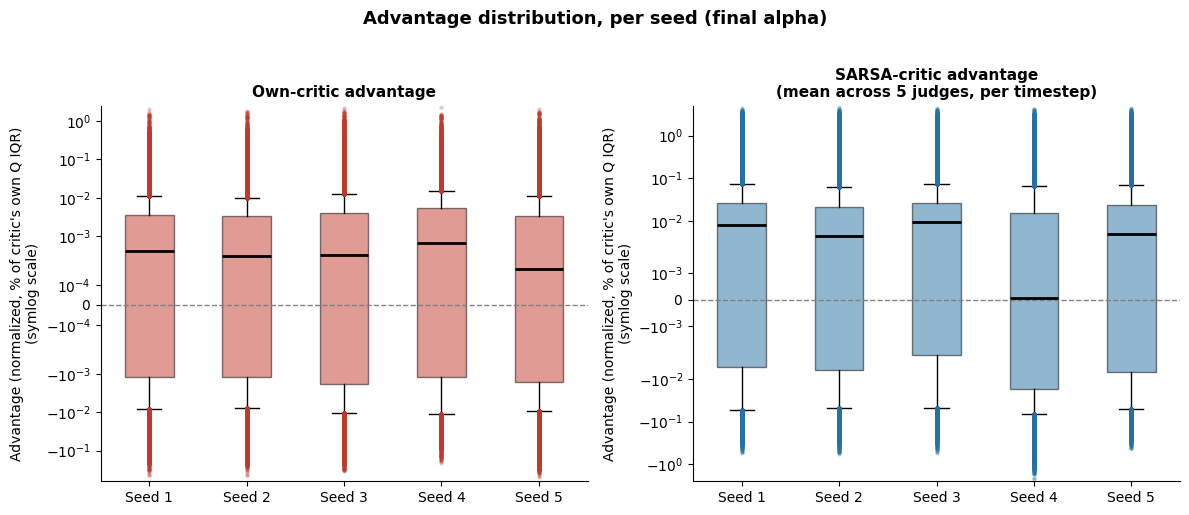

In [19]:
# reuse eval_cql's function directly, or import compute_model_advantage into this module's namespace
adv_dist.compute_model_advantage = eval_cql.compute_model_advantage

own_by_seed, sarsa_by_seed = adv_dist.compute_advantage_distributions_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    basic_q_health_score_models,
)

fig = adv_dist.plot_advantage_distributions_by_seed(
    own_by_seed, sarsa_by_seed,
    save_path=os.path.join(cql_model_dir, "advantage_distributions_by_seed_health_score.png"),
)
fig

# occupancy

Computing occupancy for seed 1/5...
  seed 1: 97.9% well-supported (min_count=10), median count=213
Computing occupancy for seed 2/5...
  seed 2: 98.7% well-supported (min_count=10), median count=287
Computing occupancy for seed 3/5...
  seed 3: 98.8% well-supported (min_count=10), median count=227
Computing occupancy for seed 4/5...
  seed 4: 93.0% well-supported (min_count=10), median count=213
Computing occupancy for seed 5/5...
  seed 5: 97.8% well-supported (min_count=10), median count=248
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/occupancy_by_seed_health_score.png


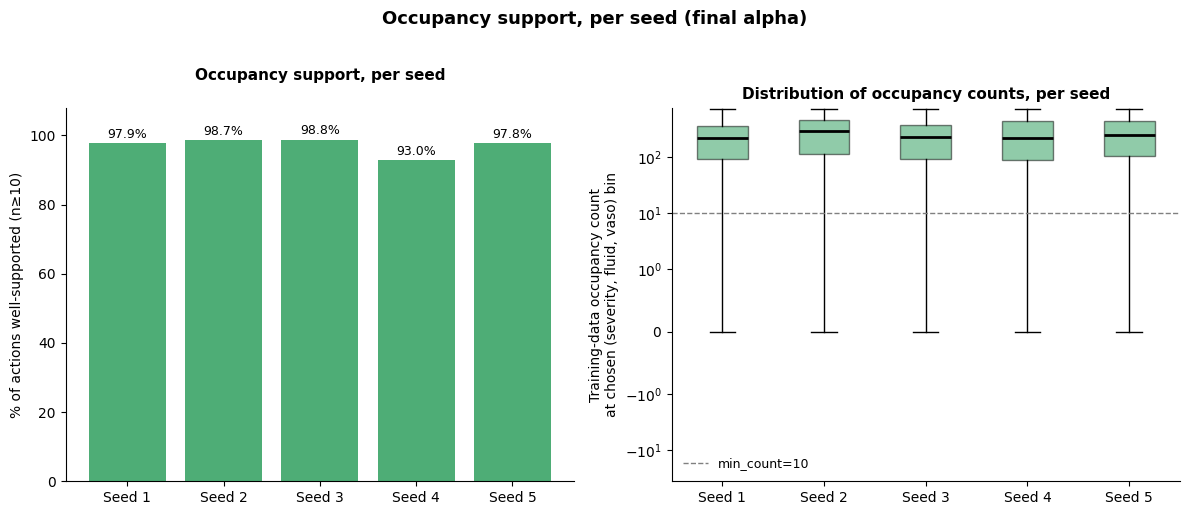

In [20]:
occ_seed.get_actor_actions = action_dist.get_actor_actions
occ_seed.compute_occupancy_support_of_actions = eval_cql.compute_occupancy_support_of_actions

support_frac_by_seed, counts_by_seed = occ_seed.compute_occupancy_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    test_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 200
)

fig = occ_seed.plot_occupancy_by_seed(
    support_frac_by_seed, counts_by_seed,
    save_path=os.path.join(cql_model_dir, "occupancy_by_seed_health_score.png"),
)
fig

# action distributions

seed 1/5: fluid[rate=99.9%, mean=0.4131, nonzero_mean=0.4135]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=99.6%, mean=0.4532, nonzero_mean=0.4549]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=99.4%, mean=0.3967, nonzero_mean=0.3993]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=100.0%, mean=0.5126, nonzero_mean=0.5129]  vaso[rate=28.7%, mean=0.0209, nonzero_mean=0.0727]
seed 5/5: fluid[rate=98.1%, mean=0.4554, nonzero_mean=0.4641]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_health_score_test.png


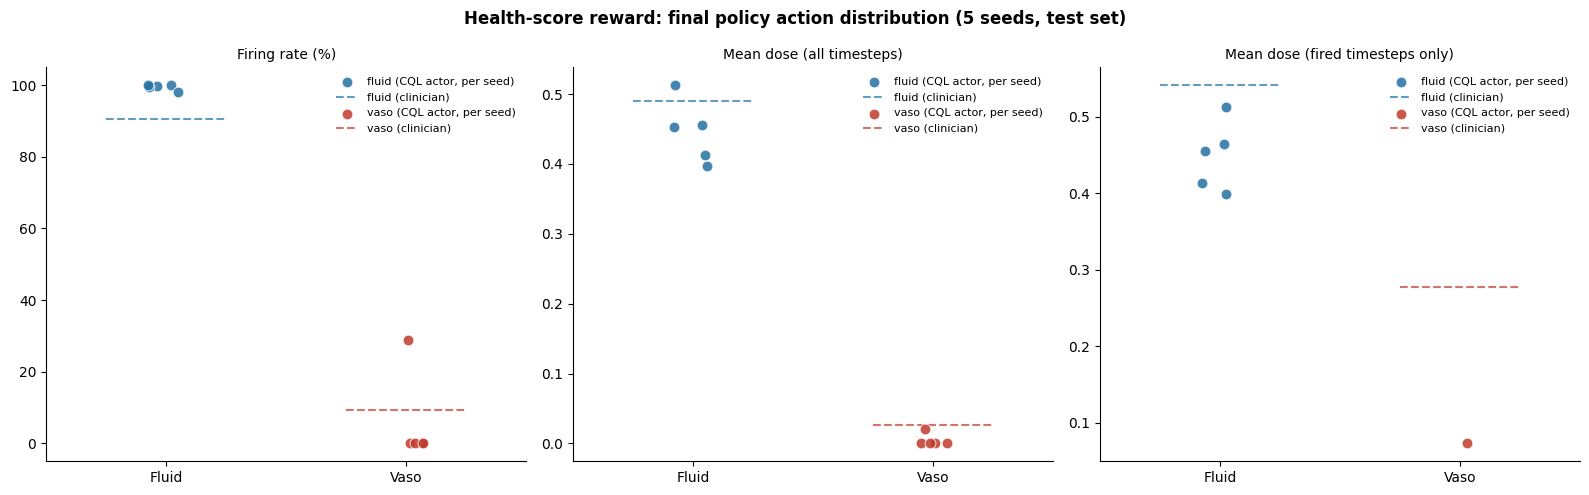

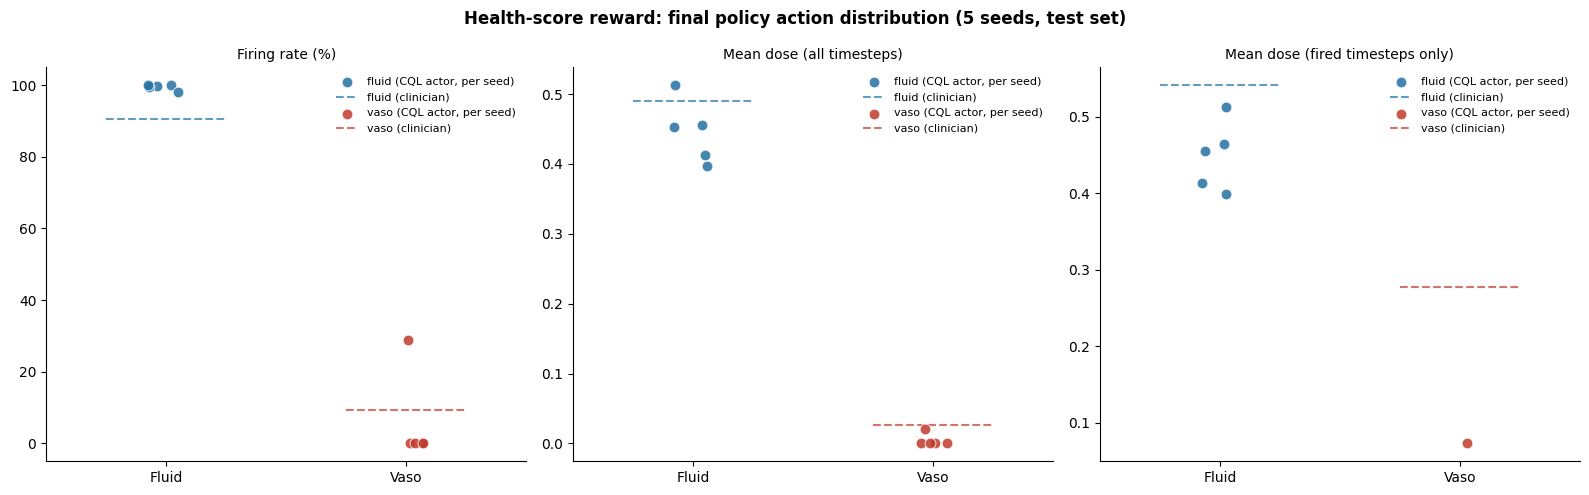

In [21]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])

stats_health_score, fig_health_score = action_dist.run_action_distribution_stage3(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Health-score reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_health_score_test.png"),
)
fig_health_score

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=105578, mean=0.5415, std=0.1455, median=0.5658, p10=0.3484, p25=0.4731, p75=0.6289, p90=0.6960
  alpha=0: n=116542, mean=0.4135, std=0.2014, median=0.4202, p10=0.1340, p25=0.3002, p75=0.5174, p90=0.6611
  alpha=1: n=116236, mean=0.4549, std=0.1870, median=0.4650, p10=0.2172, p25=0.3573, p75=0.5680, p90=0.6679
  alpha=2: n=115915, mean=0.3993, std=0.1839, median=0.4136, p10=0.1476, p25=0.2898, p75=0.5055, p90=0.6179
  alpha=3: n=116605, mean=0.5129, std=0.2024, median=0.5023, p10=0.2806, p25=0.3913, p75=0.6426, p90=0.7668
  alpha=4: n=114466, mean=0.4641, std=0.2164, median=0.4689, p10=0.1749, p25=0.3407, p75=0.5972, p90=0.7369
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_5seeds.png


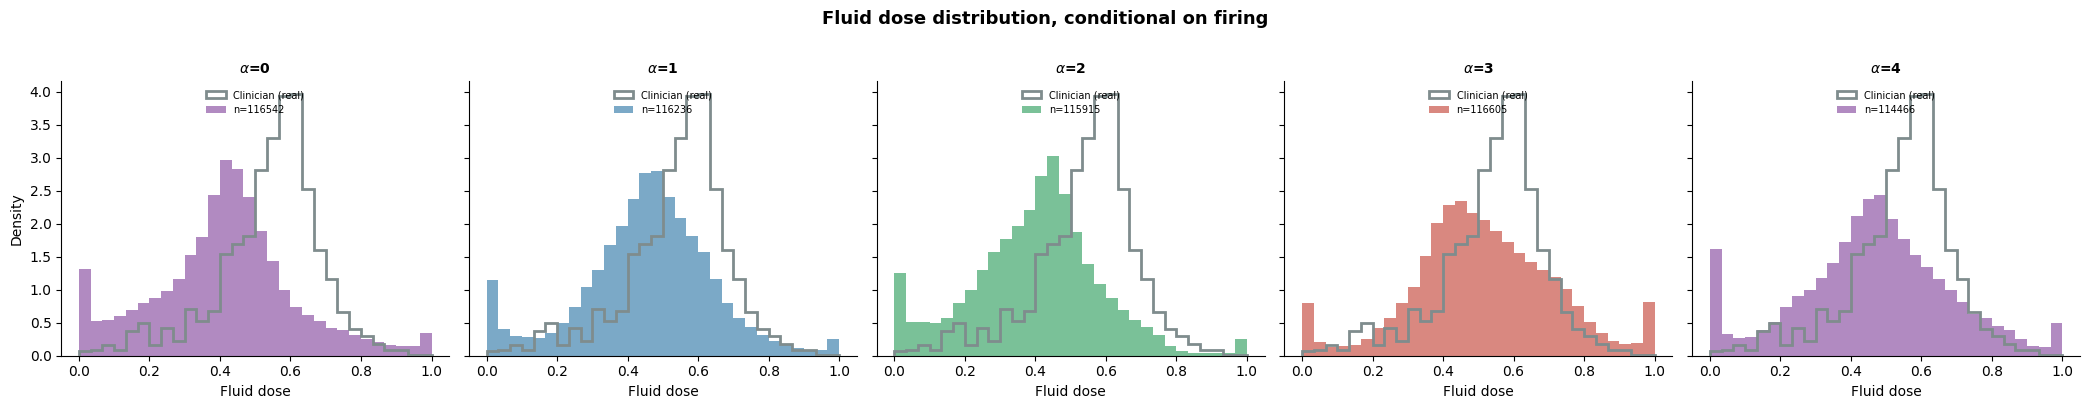

In [22]:
clinician_actions_test = processors['test'].rl_dataset["actions"]

# build a seed-keyed dict so plot_dose_histograms (originally alpha-keyed) works unchanged
cql_health_score_by_seed = {i: model_entry for i, model_entry in enumerate(cql_health_score_fixed_alpha_models)}

fig_fluid = dose_hist.plot_dose_histograms(
    cql_health_score_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    n_cols=5,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_5seeds.png"),
)

=== Vaso dose distribution summary (nonzero doses only) ===
  Clinician (real): n=10921, mean=0.2775, std=0.1371, median=0.2411, p10=0.1552, p25=0.1718, p75=0.3435, p90=0.4688
  alpha=0: no nonzero doses


/home/jake/miniconda3/envs/rl_env/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


  alpha=1: no nonzero doses
  alpha=2: no nonzero doses
  alpha=3: n=33522, mean=0.0727, std=0.0979, median=0.0200, p10=0.0002, p25=0.0010, p75=0.1190, p90=0.2169
  alpha=4: no nonzero doses
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_vaso_5seeds.png


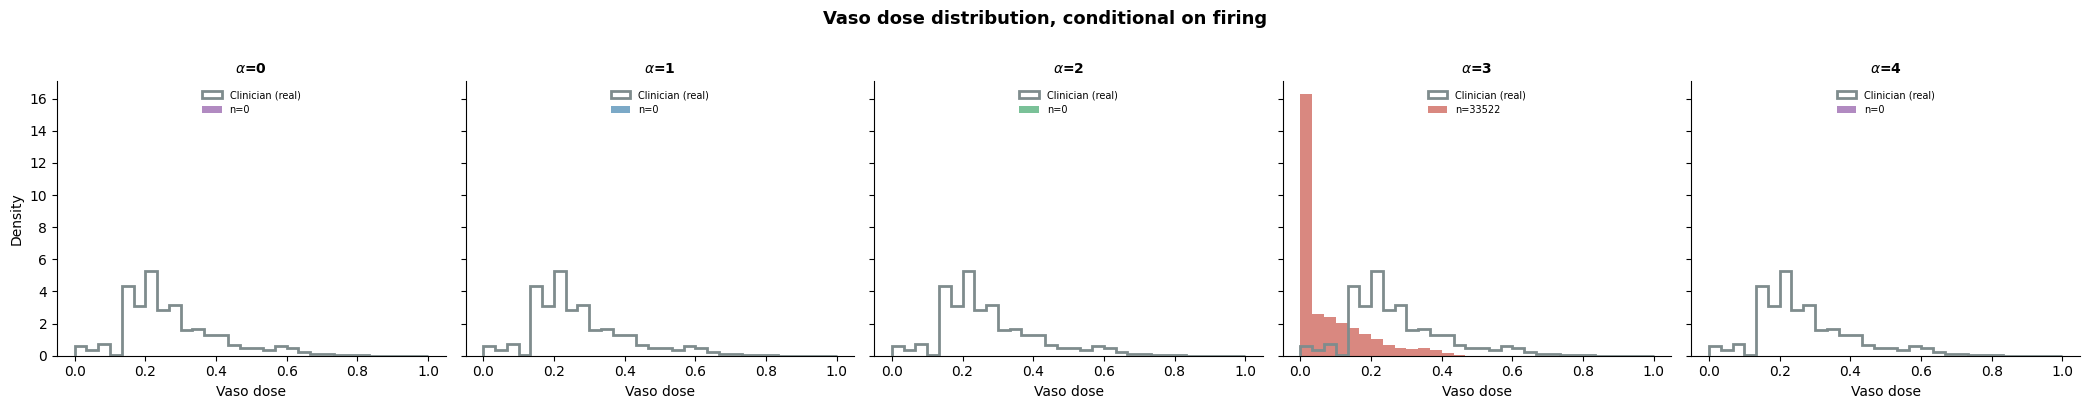

In [23]:
clinician_actions_test = processors['test'].rl_dataset["actions"]

# build a seed-keyed dict so plot_dose_histograms (originally alpha-keyed) works unchanged
cql_health_score_by_seed = {i: model_entry for i, model_entry in enumerate(cql_health_score_fixed_alpha_models)}

fig_fluid = dose_hist.plot_dose_histograms(
    cql_health_score_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=action_dist.get_actor_actions,
    n_cols=5,
    save_path=os.path.join(cql_model_dir, "dose_histogram_vaso_5seeds.png"),
)


=== Seed 0 ===
    grid point 1/20 (value=0.000)...
    grid point 2/20 (value=0.053)...
    grid point 3/20 (value=0.105)...
    grid point 4/20 (value=0.158)...
    grid point 5/20 (value=0.211)...
    grid point 6/20 (value=0.263)...
    grid point 7/20 (value=0.316)...
    grid point 8/20 (value=0.368)...
    grid point 9/20 (value=0.421)...
    grid point 10/20 (value=0.474)...
    grid point 11/20 (value=0.526)...
    grid point 12/20 (value=0.579)...
    grid point 13/20 (value=0.632)...
    grid point 14/20 (value=0.684)...
    grid point 15/20 (value=0.737)...
    grid point 16/20 (value=0.789)...
    grid point 17/20 (value=0.842)...
    grid point 18/20 (value=0.895)...
    grid point 19/20 (value=0.947)...
    grid point 20/20 (value=1.000)...
[seed0] 46697 non-monotonic timesteps out of 116662 (40.0%)
[seed0]  of non-monotonic: 7.3% convex (U-shaped), 92.7% concave (inverted-U)
[seed0]  99.0% have a genuine interior vertex (rest are edge-dominated / not a true turning poi

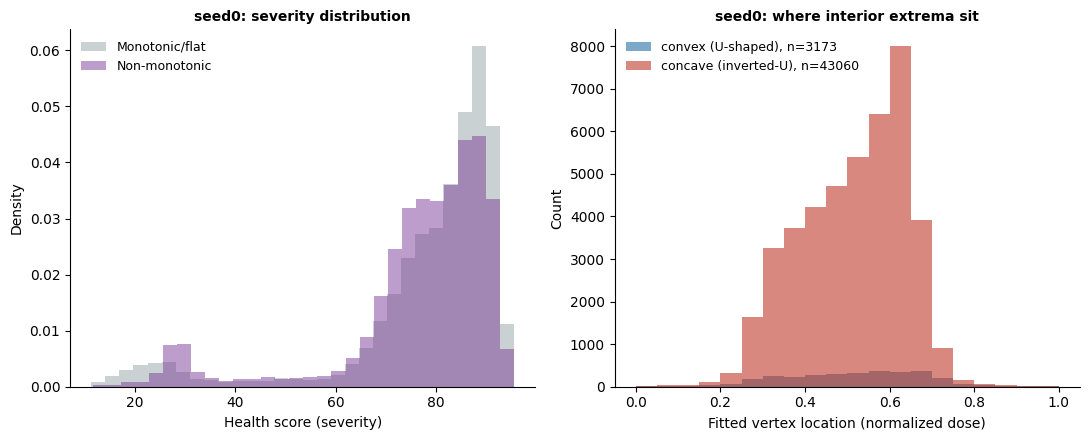

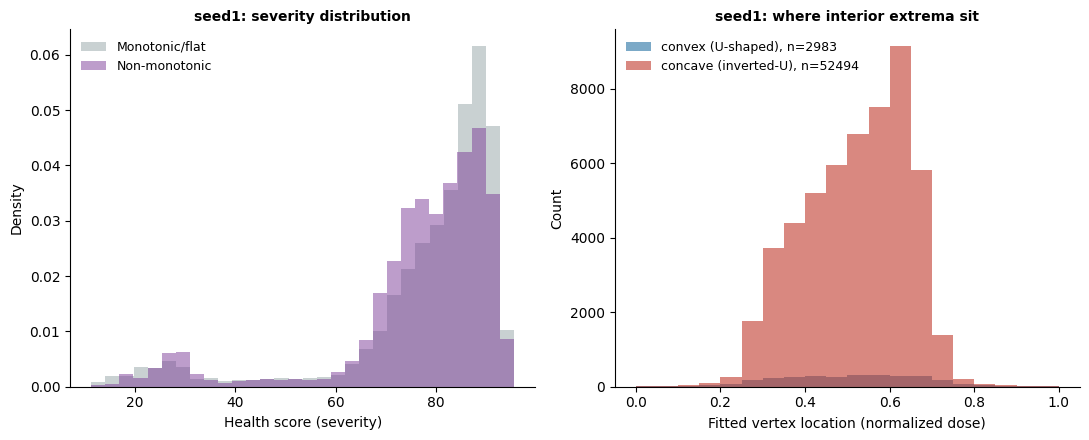

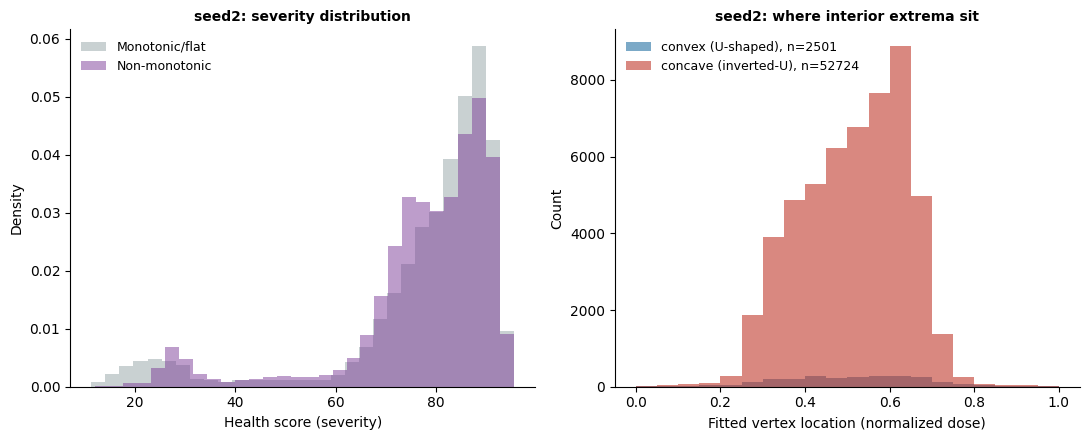

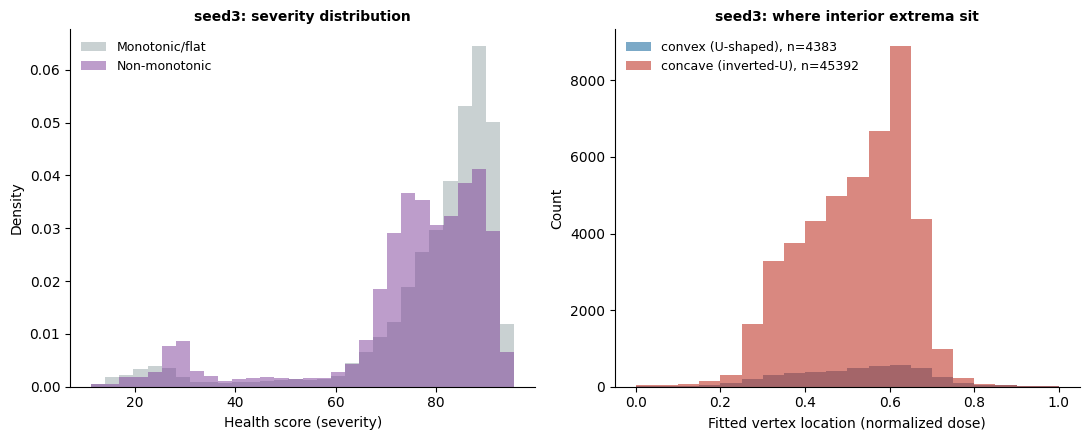

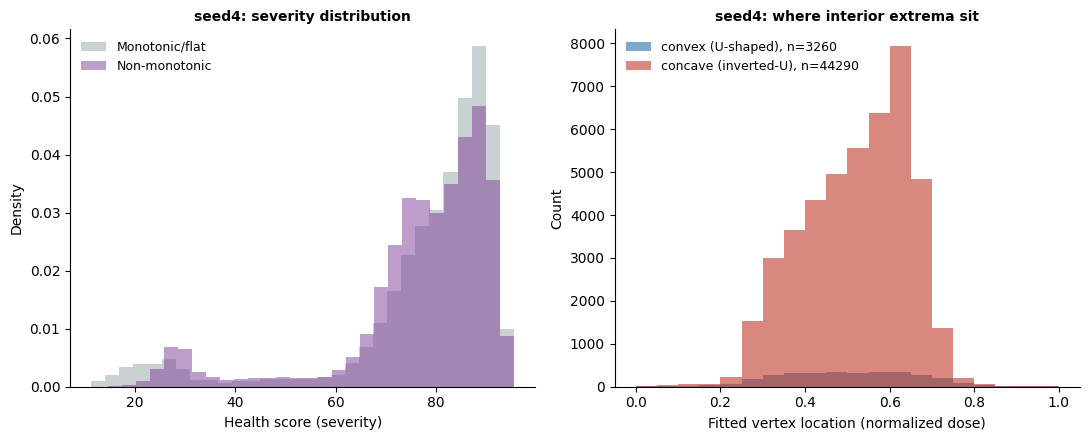

In [27]:
shape_overlap.analyze_non_monotonic_states = analyze_nm.analyze_non_monotonic_states
shape_overlap.get_actor_actions = action_dist.get_actor_actions

clinician_actions_test = processors['test'].rl_dataset["actions"]

results = shape_overlap.run_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['test'], clinician_actions_test,
    test_health_score, training_actions, training_health_score,
    save_dir=cql_model_dir,
)